# 쓰레기 이미지 12종 분류 — 데이터 전처리부터 최종 모델 학습·평가까지

**목표**: 쓰레기 사진을 12개 클래스(battery, biological, brown-glass, cardboard, clothes, green-glass, metal, paper, plastic, shoes, trash, white-glass)로 분류한다. 평가 지표는 Accuracy다.

**최종 모델**: ImageNet으로 사전학습된 ResNet18 (torchvision)
- 분류 헤드: MLP 512→256→128→12 (ReLU)
- 학습 범위: 마지막 블록(layer4)과 헤드만 학습하고, 나머지는 동결
- 입력: 224×224 / 증강: 어둡게·흐림 / 학습 데이터: 12,000장 (클래스당 1,000)

| 단계 | 내용 |
|---|---|
| 1 | 환경·경로·실행 스위치 |
| 2 | 원본 데이터(Kaggle) 분할 70/15/15 |
| 3 | 외부 데이터 통합(V2·RealWaste·AI Hub)·중복 제거 → 학습 데이터와 외부 검증셋 |
| 4 | 손상 검증셋 생성 (흐림·어둡게·빛번짐) |
| 5 | 외부 테스트셋 생성 |
| 6 | 전처리·증강 |
| 7 | 모델 정의 |
| 8 | 학습 (조기 종료) |
| 9 | 학습 곡선·과적합 확인 |
| 10 | 검증 평가 (val / val_ext / val_hard / val_avg) |
| 11 | 최종 TEST (1회) |

**실행 안내**
- **Google Colab**: 노트북만 열고 위에서부터 실행하면 된다. 1절이 Google Drive 공개 폴더 `garbage_classification`에서 데이터 zip·분할 CSV·최종 모델 가중치를 내려받아 `/content/garbage_classification`에 푼다.
  - 내 Drive에 같은 폴더가 있으면 그것을 쓰고, 없으면 공개 링크로 내려받는다.
  - Drive 폴더: https://drive.google.com/drive/folders/19R4yPCNI2B204UuINfGlBx4IZ7N2j9XB
- **로컬**: 저장소의 `01_coding/notebooks/` 폴더에서 열고 실행한다.
- AI Hub 사진은 이용약관(재배포 금지) 때문에 공개 폴더에서 내려받을 수 없다. 이 사진이 없는 환경에서는 해당 사진을 빼고 평가하고, 몇 장을 뺐는지 출력한다.
- 분할 파일(`RESULT/data_split/*.csv`)은 **한 번 만든 뒤 고정**한다. 파일이 이미 있으면 다시 만들지 않고 읽기만 한다.
- `RUN_TRAINING = False`이면 저장된 최종 모델과 학습 기록을 불러온다. 이 노트북 출력이 그 경우다. CPU 기준 학습 시간은 약 74분이다.
- TEST는 최종 모델로 **한 번만** 평가했다. 이 노트북은 그 저장된 결과를 불러온다.

## 1. 환경·경로·실행 스위치

In [1]:
# [셀 목적] 라이브러리 불러오기, 프로젝트 경로·데이터 출처 경로 지정, 실행 스위치 설정
import io
import json
import random
import time
import zipfile
from pathlib import Path

import imagehash                      # 중복 사진 탐지용 perceptual hash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image, ImageEnhance, ImageFilter, ImageOps
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

import shutil
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:  # Colab에는 한글 폰트가 없어 나눔고딕 설치
    import matplotlib.font_manager as fm
    subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-nanum"], check=False, capture_output=True)
    for f in Path("/usr/share/fonts/truetype/nanum").glob("NanumGothic*.ttf"):
        fm.fontManager.addfont(str(f))
    plt.rcParams["font.family"] = "NanumGothic"
else:
    plt.rcParams["font.family"] = "Malgun Gothic"   # 한글 폰트 (Windows)
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)

# 실행 스위치
RUN_TRAINING = False     # True: 최종 모델을 처음부터 다시 학습 (CPU 약 74분). False: 저장된 모델·학습 기록 사용
RUN_FINAL_TEST = False   # TEST는 이미 1회 평가함 → False로 두고 저장된 결과를 읽는다

# 데이터가 있는 Google Drive 공개 폴더 (zip 안의 경로 = 분할 CSV의 path 열)
DRIVE_FOLDER_ID = "19R4yPCNI2B204UuINfGlBx4IZ7N2j9XB"
DRIVE_NAME = "garbage_classification"


def fetch_drive_folder() -> Path:
    """Colab: Drive 폴더 위치를 돌려준다. 1순위 내 Drive 연결(폴더 주인), 2순위 공개 링크로 내려받기(gdown)"""
    src = Path("/content/drive/MyDrive") / DRIVE_NAME
    if not src.exists():
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive 연결 생략:", e)
    if src.exists():
        return src
    import gdown
    out = Path("/content/gc_drive")
    gdown.download_folder(id=DRIVE_FOLDER_ID, output=str(out), quiet=False)  # gdown 버전 공통 인자만 사용
    return out


def unpack_drive_data(src: Path, root: Path):
    """src의 zip을 모두 root에 풀고 최종 모델 가중치를 root/01_coding/checkpoints/에 복사 (이미 풀었으면 건너뜀)"""
    done = root / ".prepared"
    if done.exists():
        print("데이터 준비 완료 상태:", root)
        return
    root.mkdir(parents=True, exist_ok=True)
    zips = sorted(src.rglob("*.zip"))
    assert zips, f"zip 파일을 찾지 못함: {src}"
    for z in zips:
        print("압축 해제:", z.name)
        with zipfile.ZipFile(z) as zf:
            zf.extractall(root)
    weights = list(src.rglob("final_model.pth"))
    assert weights, f"final_model.pth를 찾지 못함: {src}"
    (root / "01_coding" / "checkpoints").mkdir(parents=True, exist_ok=True)
    shutil.copy(weights[0], root / "01_coding" / "checkpoints" / "final_model.pth")
    done.touch()


# 프로젝트 경로: 로컬은 저장소 루트(이 노트북 위치 = <루트>/01_coding/notebooks), Colab은 /content/garbage_classification
if IN_COLAB:
    ROOT = Path("/content") / DRIVE_NAME
    unpack_drive_data(fetch_drive_folder(), ROOT)
else:
    ROOT = Path.cwd().resolve().parents[1]
assert (ROOT / "01_coding" / "RESULT" / "data_split").exists(), f"데이터 분할 폴더가 없음: {ROOT} (로컬은 01_coding/notebooks에서 실행)"
CODING = ROOT / "01_coding"
DATA_DIR = CODING / "RESULT" / "data_split"      # 분할·데이터 목록 CSV (고정)
MODEL_DIR = CODING / "RESULT" / "final_model"    # 최종 모델 설정·학습 기록
FINAL_DIR = CODING / "RESULT" / "final_test"     # 최종 TEST 1회 결과
CKPT_PATH = CODING / "checkpoints" / "final_model.pth"   # 최종 모델 가중치 (git 제외)
PHASH_CACHE = DATA_DIR / "phash_cache.json"      # 해시 계산 캐시 (git 제외)

# 원본·외부 데이터 위치 (git 제외)
KAGGLE_DIR = ROOT / "archive" / "garbage_classification"            # Kaggle Garbage Classification 12 classes
V2_DIR = ROOT / "archive(1)" / "original"                            # Kaggle Garbage Classification V2
RW_DIR = ROOT / "realwaste" / "realwaste-main" / "RealWaste"         # RealWaste (UCI)
AIHUB_ZIP_DIR = ROOT / "232.재활용품 분류 및 선별 데이터" / "01-1.정식개방데이터"  # AI Hub 재활용품 분류 및 선별 데이터
AIHUB_OUT = ROOT / "external_data" / "aihub"      # AI Hub zip에서 꺼낸 사진 저장 위치
VAL_HARD_IMG = ROOT / "external_data" / "val_hard"  # 손상 검증셋 이미지 저장 위치

SEED = 42
CLASSES = ["battery", "biological", "brown-glass", "cardboard", "clothes", "green-glass",
           "metal", "paper", "plastic", "shoes", "trash", "white-glass"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IMG_EXT = {".jpg", ".jpeg", ".png"}
import os
torch.set_num_threads(os.cpu_count() or 1)  # CPU 스레드 = 코어 수 (로컬 12, Colab 2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # Colab GPU가 있으면 사용


def seed_everything(seed: int = SEED):
    """random / numpy / torch 난수 시드를 모두 고정해 재현성을 확보한다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def rel(p: Path) -> str:
    """프로젝트 루트 기준 상대경로('/' 구분) — CSV에 저장하는 경로 형식"""
    return p.relative_to(ROOT).as_posix()


def keep_available(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """이미지 파일이 실제로 있는 행만 남긴다. 빠진 사진(예: 공개 폴더에 없는 AI Hub)은 출처별 장수를 출력"""
    ok = df["path"].map(lambda p: (ROOT / p).exists())
    if not ok.all():
        print(f"[주의] {name}: 이미지 없음 {(~ok).sum()}장 제외 →", df.loc[~ok, "source"].value_counts().to_dict(),
              "(원래 결과와 점수가 달라질 수 있음)")
    return df[ok].reset_index(drop=True)


DATA_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print("실행 환경:", "Colab" if IN_COLAB else "로컬", "/ 장치:", DEVICE)
print("프로젝트 루트:", ROOT)
print("RUN_TRAINING =", RUN_TRAINING, "/ RUN_FINAL_TEST =", RUN_FINAL_TEST)

실행 환경: 로컬 / 장치: cpu
프로젝트 루트: D:\데이터 분석\빅데이터_프로그래밍
RUN_TRAINING = False / RUN_FINAL_TEST = False


## 2. 원본 데이터(Kaggle) 분할 — train 70 / val 15 / test 15
Kaggle 데이터의 클래스 폴더 이름이 곧 라벨이다. 층화 분할(`stratify=label`, seed 42)로 세 셋의 클래스 비율을 같게 맞춘다.
- **val** (2,327장): 깨끗한 Kaggle 사진으로 만든 기본 검증셋. 학습 중 조기 종료와 모델 선택에 쓴다.
- **test** (2,328장): 최종 평가에 한 번만 쓴다.

In [2]:
# [셀 목적] Kaggle 원본 이미지 목록을 만들고, split.csv가 없을 때만 층화 분할(70/15/15)로 생성 — 있으면 읽기만 (분할 고정)
split_path = DATA_DIR / "split.csv"
if split_path.exists():
    split = pd.read_csv(split_path)
    print("기존 split.csv 사용 (고정, 재생성 안 함)")
else:
    rows = []
    for cls_dir in sorted(p for p in KAGGLE_DIR.iterdir() if p.is_dir()):
        for f in sorted(cls_dir.iterdir()):
            if f.suffix.lower() in IMG_EXT:
                rows.append({"path": rel(f), "label": cls_dir.name, "source": "kaggle"})
    df_all = pd.DataFrame(rows)
    seed_everything(SEED)
    _train, _rest = train_test_split(df_all, test_size=0.30, stratify=df_all["label"], random_state=SEED)
    _val, _test = train_test_split(_rest, test_size=0.50, stratify=_rest["label"], random_state=SEED)
    split = pd.concat([_train.assign(split="train"), _val.assign(split="val"), _test.assign(split="test")]
                      )[["path", "label", "split", "source"]].sort_values("path").reset_index(drop=True)
    assert len(split) == len(df_all) and split["path"].is_unique
    split.to_csv(split_path, index=False, encoding="utf-8")
    print("split.csv 새로 생성")

assert sorted(split.label.unique()) == CLASSES
print("전체", len(split), "장:", split.split.value_counts().to_dict())

기존 split.csv 사용 (고정, 재생성 안 함)
전체 15515 장: {'train': 10860, 'test': 2328, 'val': 2327}


불균형: 최다 clothes 5325장 / 최소 brown-glass 607장 = 8.77배


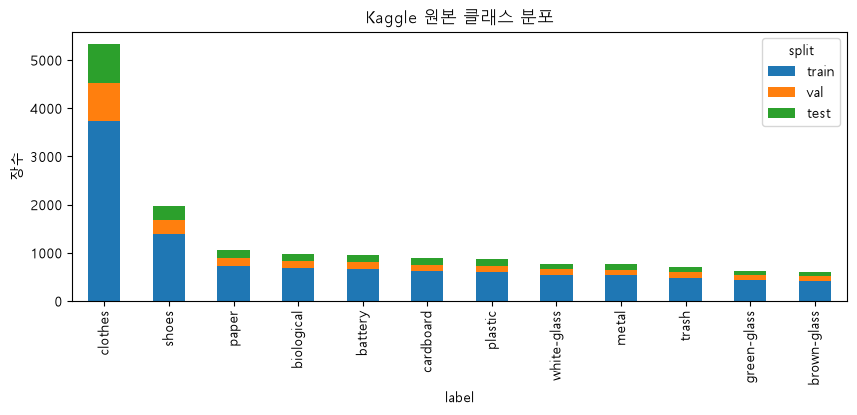

split,train,val,test,total
label,,,,
clothes,3727,799,799,5325
shoes,1384,296,297,1977
paper,735,157,158,1050
biological,689,148,148,985
battery,661,142,142,945
cardboard,624,133,134,891
plastic,606,129,130,865
white-glass,543,116,116,775
metal,538,116,115,769


In [3]:
# [셀 목적] 클래스별 장수 표와 분포 그래프 — 클래스 불균형 확인 (최다/최소 비율)
class_counts = pd.crosstab(split.label, split.split)[["train", "val", "test"]]
class_counts["total"] = class_counts.sum(axis=1)
class_counts = class_counts.sort_values("total", ascending=False)
print(f"불균형: 최다 {class_counts.total.idxmax()} {class_counts.total.max()}장 / 최소 {class_counts.total.idxmin()} "
      f"{class_counts.total.min()}장 = {class_counts.total.max() / class_counts.total.min():.2f}배")
ax = class_counts[["train", "val", "test"]].plot.bar(stacked=True, figsize=(10, 3.5), title="Kaggle 원본 클래스 분포")
ax.set_ylabel("장수")
plt.show()
class_counts

## 3. 외부 데이터 통합 → 학습 데이터(train_mix)와 외부 검증셋(val_ext)
Kaggle 사진은 대부분 단색 배경이라, 실제 환경 사진이나 생성형 이미지와 분위기가 다르다. 그래서 실사 외부 데이터를 섞는다.

| 출처 | 사용 클래스 | 비고 |
|---|---|---|
| Garbage Classification V2 (Kaggle, sumn2u) | biological·cardboard·metal·paper·plastic·trash | glass는 색 라벨이 없어 제외 |
| RealWaste (UCI, CC BY-NC-SA 4.0) | Food Organics→biological, Misc Trash→trash, Cardboard·Metal·Paper·Plastic | Glass·Vegetation·Textile 제외 |
| AI Hub 재활용품 분류 및 선별 데이터 (직접촬영) | 유리병 갈색·녹색·투명(→white-glass), 건전지(→battery), 철캔(→metal) | zip에서 필요한 만큼만 꺼내 짧은 변 384px로 저장 |

**처리 순서**
1. **중복 제거**: perceptual hash 거리 4 이하를 같은 사진으로 본다.
   - Kaggle 전체(train·val·test)와 겹치는 외부 사진은 제거한다. 라벨이 다르면 '충돌'로 보고 제외한다.
   - 외부 사진끼리 겹칠 때도 같은 기준으로 처리한다.
   - 이렇게 해야 검증·테스트 사진이 학습 데이터로 새어 들어가지 않는다.
2. **외부 검증셋 val_ext를 먼저 떼어 고정**: RealWaste·AI Hub에서 클래스당 50장씩 10클래스, 총 500장이다.
3. **학습 데이터 train_mix 구성**: 남은 외부 사진과 Kaggle train을 섞어 클래스당 1,000장, 총 12,000장을 만든다. 외부 사진이 모자라면 Kaggle로 채운다.

In [4]:
# [셀 목적] 외부 데이터 설정값 — 클래스 매핑, AI Hub zip 목록, 클래스별 학습 데이터 구성표, 외부 검증셋 구성표
HAM = 4  # 중복 판정 hamming 거리
V2_MAP = {c: c for c in ["biological", "cardboard", "metal", "paper", "plastic", "trash"]}
RW_MAP = {"Food Organics": "biological", "Miscellaneous Trash": "trash", "Cardboard": "cardboard",
          "Metal": "metal", "Paper": "paper", "Plastic": "plastic"}
# AI Hub zip → (클래스, 꺼낼 후보 수). 후보 수 = 필요량 × 약 1.35 (중복 제거 여유분)
AI_ZIPS = [
    ("Validation/01.원천데이터/VS_2.직접촬영_07.유리병_001.갈색.zip", "brown-glass", 850),
    ("Validation/01.원천데이터/VS_2.직접촬영_07.유리병_002.녹색.zip", "green-glass", 830),
    ("Validation/01.원천데이터/VS_2.직접촬영_07.유리병_003.투명.zip", "white-glass", 810),
    ("Training/01.원천데이터/TS_2.직접촬영_08.건전지_001.건전지.zip", "battery", 650),
    ("Validation/01.원천데이터/VS_2.직접촬영_08.건전지_001.건전지.zip", "battery", 150),
    ("Training/01.원천데이터/TS_2.직접촬영_01.금속캔_001.철캔_3.zip", "metal", 200),
]
# 학습 데이터 구성표: 클래스 → {출처: 장수} (클래스당 1,000장, 외부 약 47%)
TRAIN_PLAN = {
    "battery": {"kaggle": 500, "aihub": 500},
    "biological": {"kaggle": 579, "v2": 60, "realwaste": 361},
    "brown-glass": {"kaggle": 425, "aihub": 575},
    "green-glass": {"kaggle": 440, "aihub": 560},
    "white-glass": {"kaggle": 450, "aihub": 550},
    "cardboard": {"kaggle": 400, "v2": 300, "realwaste": 300},
    "clothes": {"kaggle": 1000},
    "metal": {"kaggle": 400, "v2": 200, "realwaste": 300, "aihub": 100},
    "paper": {"kaggle": 400, "v2": 300, "realwaste": 300},
    "plastic": {"kaggle": 400, "v2": 300, "realwaste": 300},
    "shoes": {"kaggle": 1000},
    "trash": {"kaggle": 400, "v2": 200, "realwaste": 400},
}
# 외부 검증셋 구성표: clothes·shoes는 RealWaste·AI Hub에 없어 제외 (10클래스 × 50 = 500)
VAL_EXT_PLAN = {
    "battery": {"aihub": 50}, "brown-glass": {"aihub": 50}, "green-glass": {"aihub": 50},
    "white-glass": {"aihub": 50}, "biological": {"realwaste": 50}, "trash": {"realwaste": 50},
    "cardboard": {"realwaste": 50}, "paper": {"realwaste": 50}, "plastic": {"realwaste": 50},
    "metal": {"realwaste": 25, "aihub": 25},
}

In [5]:
# [셀 목적] 외부 데이터 처리 함수 — AI Hub zip 추출, 폴더 목록화, perceptual hash 계산, 최소 해시 거리 계산
def extract_aihub() -> pd.DataFrame:
    """AI Hub zip에서 seed 고정으로 필요한 수만 꺼내 짧은 변 384px JPEG로 저장 (이미 있으면 건너뜀)"""
    rows = []
    for zrel, label, n in AI_ZIPS:
        out_dir = AIHUB_OUT / label
        out_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(AIHUB_ZIP_DIR / zrel) as zf:
            names = sorted(i.filename for i in zf.infolist() if not i.is_dir() and i.filename.lower().endswith(".jpg"))
            pick = random.Random(SEED).sample(names, min(n, len(names)))
            broken = 0
            for name in pick:
                dst = out_dir / Path(name).name
                if not dst.exists():
                    try:
                        img = Image.open(io.BytesIO(zf.read(name)))
                        img.draft("RGB", (768, 768))  # 큰 JPEG를 빠르게 축소 디코딩
                        img = ImageOps.exif_transpose(img).convert("RGB")
                    except Exception:  # zip 안의 깨진 파일은 건너뜀
                        broken += 1
                        continue
                    s = 384 / min(img.size)
                    if s < 1:
                        img = img.resize((round(img.width * s), round(img.height * s)), Image.BILINEAR)
                    img.save(dst, quality=92)
                rows.append(dict(path=rel(dst), label=label, source="aihub", origin=f"{Path(zrel).name}/{name}"))
    return pd.DataFrame(rows)


def list_folder(base: Path, mapping: dict, source: str) -> pd.DataFrame:
    """원본 폴더(클래스별 하위 폴더)를 우리 12클래스 라벨로 매핑해 목록화"""
    rows = []
    for src_cls, label in mapping.items():
        for f in sorted((base / src_cls).iterdir()):
            if f.suffix.lower() in IMG_EXT:
                rows.append(dict(path=rel(f), label=label, source=source, origin=f"{src_cls}/{f.name}"))
    return pd.DataFrame(rows)


def phash_all(paths, cache: dict) -> np.ndarray:
    """각 이미지의 64bit perceptual hash (캐시에 있으면 재사용)"""
    out = np.zeros(len(paths), dtype=np.uint64)
    for i, p in enumerate(paths):
        if p not in cache:
            with Image.open(ROOT / p) as im:
                im.draft("L", (128, 128))
                cache[p] = str(imagehash.phash(im.convert("L")))
        out[i] = np.uint64(int(cache[p], 16))
    return out


def min_ham(a: np.ndarray, b: np.ndarray, chunk=400):
    """a의 각 해시에 대해 b 중 가장 가까운 hamming 거리와 그 위치 (메모리 절약을 위해 400개씩 나눠 계산)"""
    dmin = np.full(len(a), 99, dtype=np.int64)
    arg = np.zeros(len(a), dtype=np.int64)
    for s in range(0, len(a), chunk):
        d = np.bitwise_count(a[s:s + chunk, None] ^ b[None, :]).astype(np.int64)
        arg[s:s + chunk] = d.argmin(1)
        dmin[s:s + chunk] = d.min(1)
    return dmin, arg

In [6]:
# [셀 목적] train_mix.csv·val_ext.csv가 없을 때만: 중복 제거 → 외부 검증셋 고정 → 학습 데이터 12,000장 구성. 있으면 읽기만
mix_path, val_ext_path = DATA_DIR / "train_mix.csv", DATA_DIR / "val_ext.csv"
if mix_path.exists() and val_ext_path.exists():
    train_mix, val_ext = pd.read_csv(mix_path), pd.read_csv(val_ext_path)
    print("기존 train_mix.csv·val_ext.csv 사용 (고정, 재생성 안 함)")
else:
    random.seed(SEED)
    ext = pd.concat([list_folder(V2_DIR, V2_MAP, "v2"), list_folder(RW_DIR, RW_MAP, "realwaste"), extract_aihub()],
                    ignore_index=True)
    cache = json.loads(PHASH_CACHE.read_text()) if PHASH_CACHE.exists() else {}
    hk = phash_all(split["path"].tolist(), cache)
    he = phash_all(ext["path"].tolist(), cache)
    PHASH_CACHE.write_text(json.dumps(cache))

    # ① Kaggle 전체(train·val·test)와 비교: 같은 라벨 근접 = 중복, 다른 라벨 근접 = 라벨 충돌 → 둘 다 제외
    d, j = min_ham(he, hk)
    near = d <= HAM
    same = near & (split["label"].values[j] == ext["label"].values)
    ext["status"] = "keep"
    ext.loc[same, "status"] = "dup_kaggle"
    ext.loc[near & ~same, "status"] = "conflict_kaggle"

    # ② 외부끼리 비교: 같은 라벨 근접 → 1장만 유지(AI Hub > RealWaste > V2 우선), 다른 라벨 근접 → 양쪽 제외
    idx = np.where(ext["status"] == "keep")[0]
    h = he[idx]
    labels = ext["label"].values[idx]
    order = {"aihub": 0, "realwaste": 1, "v2": 2}
    pri = np.array([order[s] for s in ext["source"].values[idx]])
    drop_dup, drop_conf = set(), set()
    for s in range(0, len(idx), 400):
        dd = np.bitwise_count(h[s:s + 400, None] ^ h[None, :])
        for r, c in zip(*np.where(dd <= HAM)):
            a, b = s + r, c
            if a >= b:
                continue
            if labels[a] != labels[b]:
                drop_conf.update([a, b])
            else:
                drop_dup.add(b if (pri[a], a) <= (pri[b], b) else a)
    ext.loc[idx[sorted(drop_dup - drop_conf)], "status"] = "dup_external"
    ext.loc[idx[sorted(drop_conf)], "status"] = "conflict_external"
    report = ext.pivot_table(index=["source", "label"], columns="status", values="path", aggfunc="count", fill_value=0)
    report.to_csv(DATA_DIR / "dedup_report.csv", encoding="utf-8-sig")
    pool = ext[ext["status"] == "keep"].copy()

    # ③ 외부 검증셋(val_ext) 먼저 고정
    ve = []
    for label, srcs in VAL_EXT_PLAN.items():
        for src, n in srcs.items():
            cand = pool[(pool.label == label) & (pool.source == src)]
            ve.append(cand.sample(n=min(n, len(cand)), random_state=SEED))
    val_ext = pd.concat(ve)
    pool = pool.drop(val_ext.index)

    # ④ 학습 데이터: 구성표대로 외부 사진을 뽑고, 모자란 만큼 Kaggle train으로 채워 클래스당 1,000장
    k_train = split[split["split"] == "train"]
    tr = []
    for label, srcs in TRAIN_PLAN.items():
        got = 0
        for src, n in srcs.items():
            if src == "kaggle":
                continue
            cand = pool[(pool.label == label) & (pool.source == src)]
            take = cand.sample(n=min(n, len(cand)), random_state=SEED)
            tr.append(take)
            got += len(take)
        kc = k_train[k_train.label == label]
        tr.append(kc.sample(n=min(1000 - got, len(kc)), random_state=SEED).assign(origin="split.csv"))
    train_mix = pd.concat(tr)

    cols = ["path", "label", "split", "source"]
    train_mix = train_mix.assign(split="train")[cols].sort_values(["label", "source", "path"]).reset_index(drop=True)
    val_ext = val_ext.assign(split="val_ext")[cols].sort_values(["label", "source", "path"]).reset_index(drop=True)
    train_mix.to_csv(mix_path, index=False, encoding="utf-8")
    val_ext.to_csv(val_ext_path, index=False, encoding="utf-8")
    print("train_mix.csv·val_ext.csv 새로 생성")

# 누출 검사: 학습 데이터 ∩ 외부 검증셋 = ∅, 외부 검증셋 ∩ Kaggle = ∅, 학습 데이터의 Kaggle 사진은 Kaggle train에서만
assert not set(train_mix.path) & set(val_ext.path)
assert not set(val_ext.path) & set(split.path)
assert set(train_mix[train_mix.source == "kaggle"].path) <= set(split[split.split == "train"].path)
print("학습 데이터", len(train_mix), "장:", train_mix.source.value_counts().to_dict())
print("외부 검증셋", len(val_ext), "장:", val_ext.source.value_counts().to_dict())
pd.crosstab(train_mix.label, train_mix.source)

기존 train_mix.csv·val_ext.csv 사용 (고정, 재생성 안 함)
학습 데이터 12000 장: {'kaggle': 6396, 'aihub': 2285, 'realwaste': 1959, 'v2': 1360}
외부 검증셋 500 장: {'realwaste': 275, 'aihub': 225}


source,aihub,kaggle,realwaste,v2
label,,,,
battery,500,500,0,0
biological,0,581,359,60
brown-glass,575,425,0,0
cardboard,0,400,300,300
clothes,0,1000,0,0
green-glass,560,440,0,0
metal,100,400,300,200
paper,0,400,300,300
plastic,0,400,300,300


In [7]:
# [셀 목적] 중복 제거 결과 표 — 출처·클래스별로 유지(keep) / Kaggle 중복 / 라벨 충돌 / 외부끼리 중복 장수
pd.read_csv(DATA_DIR / "dedup_report.csv", index_col=[0, 1])

conflict_external  conflict_kaggle  dup_external  dup_kaggle  keep
source    label                                                                          
aihub     battery                      3                2             1           0   794
          brown-glass                  6                5             2           0   837
          green-glass                  5                0             2           0   822
          metal                        1                0             1           0   198
          white-glass                  2                0             0           0   808
realwaste biological                   0                0             2           0   409
          cardboard                    2                0             0           0   459
          metal                        2                1             1           0   786
          paper                        0                0             0           0   500
          plastic                      4                2             6           0   909
          trash                        0                3             1           0   491
v2        biological                   0                0             0         639    60
          cardboard                    0                5             0         710   696
          metal                        0                0             0         611   319
          paper                        1                1             0         603   731
          plastic                      0                0             0         633   964
          trash                        0                0             0         231   222

## 4. 손상 검증셋(val_hard) 생성 — 어둡거나 흐리거나 빛이 번진 사진
채점 이미지에는 어둡거나 흐린 사진이 섞일 수 있다. 이런 사진에서 모델이 얼마나 버티는지 따로 재기 위해 고정된 손상 검증셋을 만든다.
- **구성** (1,200장)
  - Kaggle val에서 클래스당 50장. clothes·shoes는 외부 사진이 없어 100장씩 → 700장
  - 외부 검증셋 500장
- **손상**: 160×160으로 줄인 뒤 seed를 고정해 3종 중 하나를 적용한다.
  - 흐림: Gaussian 반경 2~3
  - 어둡게: 밝기 0.15~0.35배
  - 빛번짐: 흰 원형 광원 합성
- 학습 증강(밝기 0.3~1.0, 흐림 σ 0.5~2)보다 **더 강하게** 만들었다. 빛번짐은 학습에 아예 없는 손상이라, 처음 보는 손상에 대한 일반화도 볼 수 있다.

In [8]:
# [셀 목적] 손상 함수(흐림·어둡게·빛번짐) 정의 + val_hard.csv가 없을 때만 손상 이미지 1,200장 생성 (있으면 읽기만)
def glare(img: Image.Image, rng: random.Random) -> Image.Image:
    """무작위 위치에 흰 원형 빛번짐을 screen 합성"""
    a = np.asarray(img, dtype=np.float32) / 255.0
    h, w = a.shape[:2]
    cy, cx = rng.uniform(0.15, 0.85) * h, rng.uniform(0.15, 0.85) * w
    r = rng.uniform(0.25, 0.45) * min(h, w)
    yy, xx = np.mgrid[0:h, 0:w]
    m = np.clip(1 - np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2) / r, 0, 1) ** 1.5 * rng.uniform(0.6, 0.9)
    a = 1 - (1 - a) * (1 - m[..., None])
    return Image.fromarray((a * 255).clip(0, 255).astype(np.uint8))


def corrupt(img: Image.Image, kind: str, rng: random.Random) -> Image.Image:
    if kind == "blur":
        return img.filter(ImageFilter.GaussianBlur(rng.uniform(2.0, 3.0)))
    if kind == "dark":
        return ImageEnhance.Brightness(img).enhance(rng.uniform(0.15, 0.35))
    return glare(img, rng)


val_hard_path = DATA_DIR / "val_hard.csv"
if val_hard_path.exists():
    val_hard = pd.read_csv(val_hard_path)
    print("기존 val_hard.csv 사용 (고정, 재생성 안 함)")
else:
    val = split[split["split"] == "val"]
    parts = [g.sample(n=100 if c in ("clothes", "shoes") else 50, random_state=SEED) for c, g in val.groupby("label")]
    src = pd.concat(parts + [val_ext], ignore_index=True).sort_values(["label", "source", "path"]).reset_index(drop=True)
    rng = random.Random(SEED)
    rows = []
    for i, r in src.iterrows():
        kind = rng.choice(["blur", "dark", "glare"])
        img = Image.open(ROOT / r.path).convert("RGB").resize((160, 160), Image.BILINEAR)
        p = VAL_HARD_IMG / r.label / f"{i:04d}_{kind}.png"
        p.parent.mkdir(parents=True, exist_ok=True)
        corrupt(img, kind, rng).save(p)
        rows.append(dict(path=rel(p), label=r.label, split="val_hard", source=r.source, orig_path=r.path, corruption=kind))
    val_hard = pd.DataFrame(rows)
    val_hard.to_csv(val_hard_path, index=False, encoding="utf-8")
    print("val_hard.csv 새로 생성")

print("손상 검증셋", len(val_hard), "장 | 손상별", val_hard.corruption.value_counts().to_dict(),
      "| 출처별", val_hard.source.value_counts().to_dict())

기존 val_hard.csv 사용 (고정, 재생성 안 함)
손상 검증셋 1200 장 | 손상별 {'dark': 408, 'glare': 397, 'blur': 395} | 출처별 {'kaggle': 700, 'realwaste': 275, 'aihub': 225}


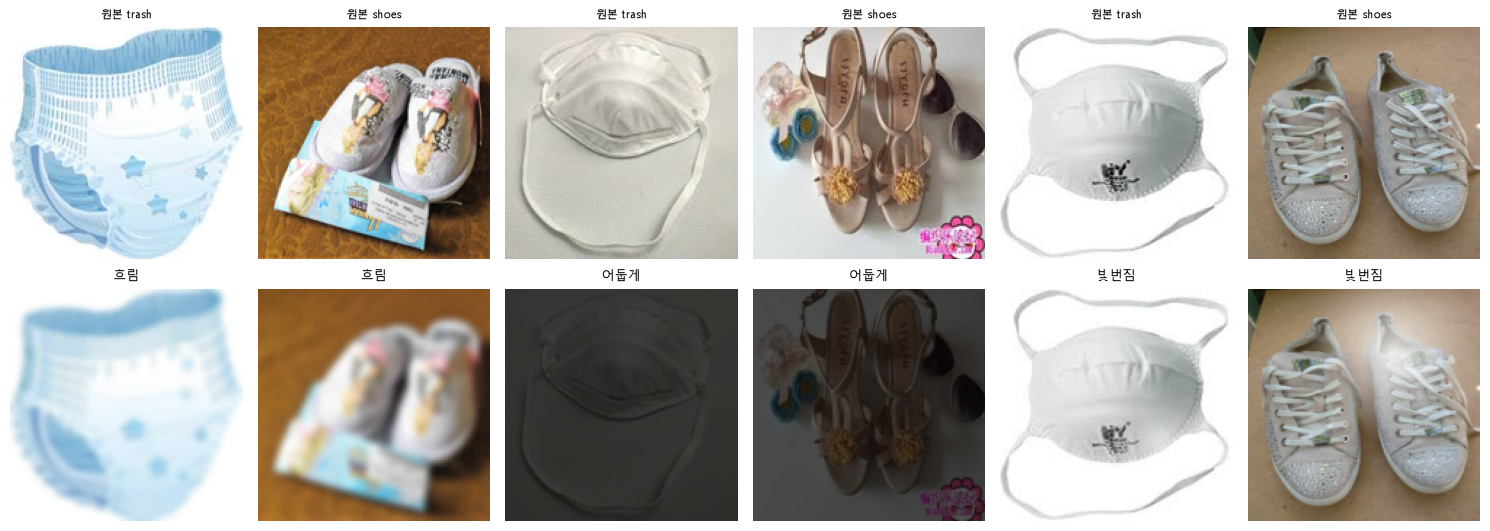

In [9]:
# [셀 목적] 손상 검증셋 예시 — 원본(위)과 손상 버전(아래) 6쌍 (이미지 파일이 있을 때만 표시)
ex = pd.concat([val_hard[val_hard.corruption == k].drop_duplicates("label").sample(2, random_state=SEED)
                for k in ["blur", "dark", "glare"]])  # 손상 종류마다 서로 다른 클래스 2장
if all((ROOT / p).exists() for p in list(ex.path) + list(ex.orig_path)):
    fig, ax = plt.subplots(2, 6, figsize=(15, 5.5))
    for k, r in enumerate(ex.itertuples()):
        ax[0, k].imshow(Image.open(ROOT / r.orig_path).convert("RGB").resize((160, 160)))
        ax[0, k].set_title(f"원본 {r.label}", fontsize=8)
        ax[1, k].imshow(Image.open(ROOT / r.path))
        ax[1, k].set_title({"blur": "흐림", "dark": "어둡게", "glare": "빛번짐"}[r.corruption], fontsize=9)
    for a in ax.ravel():
        a.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("이미지 파일이 없어 예시를 생략 (저장소에는 이미지 미포함)")

## 5. 외부 테스트셋(test_ext) 생성 — 최종 평가 보조용
Kaggle test는 깨끗한 사진뿐이라, 실제 채점 이미지(생성형·실사)에 가까운 외부 사진으로도 최종 점수를 확인한다.
- **구성**: 학습 데이터와 외부 검증셋에 쓰지 않고 남은 외부 사진(AI Hub·RealWaste)에서 9클래스 × 40장 = 360장
  - biological·clothes·shoes는 남은 외부 사진이 없어 제외했다.
- **안전 재검사**: Kaggle 전체, 학습 데이터, 외부 검증셋과 해시가 가까운 사진은 뺀다. 남은 사진끼리 가까운 쌍도 둘 다 뺀다(같은 물체를 반복 촬영한 사진 방지).
- 학습·모델 선택에는 쓰지 않고, **Kaggle test와 함께 마지막에 한 번만** 평가한다.

In [10]:
# [셀 목적] test_ext.csv가 없을 때만: 남은 외부 사진에서 해시 재검사 후 9클래스 × 40장 추출 (있으면 읽기만)
TEST_EXT_PLAN = {
    "battery": {"aihub": 40}, "brown-glass": {"aihub": 40}, "green-glass": {"aihub": 40},
    "white-glass": {"aihub": 40}, "metal": {"aihub": 20, "realwaste": 20},
    "cardboard": {"realwaste": 40}, "paper": {"realwaste": 40}, "plastic": {"realwaste": 40},
    "trash": {"realwaste": 40},
}
test_ext_path = DATA_DIR / "test_ext.csv"
if test_ext_path.exists():
    test_ext = pd.read_csv(test_ext_path)
    print("기존 test_ext.csv 사용 (고정, 재생성 안 함)")
else:
    used = set(train_mix.path) | set(val_ext.path)
    aihub_files = pd.DataFrame([dict(path=rel(f), label=d.name, source="aihub")
                                for d in sorted(AIHUB_OUT.iterdir()) if d.is_dir() for f in sorted(d.iterdir())])
    ext = pd.concat([list_folder(V2_DIR, V2_MAP, "v2"), list_folder(RW_DIR, RW_MAP, "realwaste"), aihub_files],
                    ignore_index=True)[["path", "label", "source"]]
    ext = ext[~ext.path.isin(used)].reset_index(drop=True)
    cache = json.loads(PHASH_CACHE.read_text())
    he = phash_all(ext.path.tolist(), cache)
    ref = pd.concat([split[["path"]], train_mix[["path"]], val_ext[["path"]]]).drop_duplicates()
    hr = phash_all(ref.path.tolist(), cache)
    PHASH_CACHE.write_text(json.dumps(cache))
    d, _ = min_ham(he, hr)
    keep = d > HAM                                   # 이미 쓰인 사진·Kaggle 전체와 근접 → 제외
    if len(he) < 6000:                               # 풀 내부 근접쌍 → 양쪽 제외
        dd = np.bitwise_count(he[:, None] ^ he[None, :])
        np.fill_diagonal(dd, 99)
        keep &= dd.min(1) > HAM
    ext = ext[keep].reset_index(drop=True)
    te = []
    for label, srcs in TEST_EXT_PLAN.items():
        for src, n in srcs.items():
            cand = ext[(ext.label == label) & (ext.source == src)]
            assert len(cand) >= n, f"{label}/{src}: {len(cand)} < {n}"
            te.append(cand.sample(n=n, random_state=SEED))
    test_ext = pd.concat(te).assign(split="test_ext")[["path", "label", "split", "source"]].sort_values(["label", "source", "path"]).reset_index(drop=True)
    test_ext.to_csv(test_ext_path, index=False, encoding="utf-8")
    print("test_ext.csv 새로 생성")

# 누출 검사: 외부 테스트셋은 학습 데이터·외부 검증셋·Kaggle 어디에도 없어야 함
assert not set(test_ext.path) & (set(train_mix.path) | set(val_ext.path) | set(split.path))
print("외부 테스트셋", len(test_ext), "장:", test_ext.source.value_counts().to_dict())

기존 test_ext.csv 사용 (고정, 재생성 안 함)
외부 테스트셋 360 장: {'aihub': 180, 'realwaste': 180}


### 데이터셋 정리

| 이름 | 장수 | 구성 | 용도 |
|---|---|---|---|
| 학습 데이터 (train_mix) | 12,000 | Kaggle 6,396 · AI Hub 2,285 · RealWaste 1,959 · V2 1,360 | 학습 |
| **val** — 기본 검증 | 2,327 | Kaggle 원본 분할 15% (깨끗한 사진) | 조기 종료·선택 |
| **val_ext** — 외부 검증 | 500 | RealWaste·AI Hub 실사 사진 (10클래스) | 조기 종료·선택 |
| **val_hard** — 손상 검증 | 1,200 | val·val_ext 사진을 흐림·어둡게·빛번짐으로 손상 | 선택 |
| **test** — 기본 테스트 | 2,328 | Kaggle 원본 분할 15% | 최종 1회 |
| **test_ext** — 외부 테스트 | 360 | RealWaste·AI Hub 실사 사진 (9클래스) | 최종 1회 |

In [11]:
# [셀 목적] 모든 데이터셋의 장수·클래스 수를 한 표로 확인
sets_summary = pd.DataFrame({
    "장수": [len(train_mix), (split.split == "val").sum(), len(val_ext), len(val_hard), (split.split == "test").sum(), len(test_ext)],
    "클래스 수": [train_mix.label.nunique(), split[split.split == "val"].label.nunique(), val_ext.label.nunique(),
               val_hard.label.nunique(), split[split.split == "test"].label.nunique(), test_ext.label.nunique()],
}, index=["학습 데이터", "val", "val_ext", "val_hard", "test", "test_ext"])
sets_summary

,장수,클래스 수
학습 데이터,12000,12
val,2327,12
val_ext,500,10
val_hard,1200,12
test,2328,12
test_ext,360,9


## 6. 전처리·증강
- **공통 전처리**: 224×224로 리사이즈한 뒤, ImageNet 평균·표준편차로 정규화한다.
- **학습 증강 (어둡게·흐림)**: 사진마다 50% 확률로 아래 둘 중 하나를 적용한다.
  - 어둡게: 밝기를 원래의 30~100%로 낮춘다.
  - 흐림: Gaussian blur (커널 5, σ 0.5~2)
  - 어둡거나 흐린 채점 사진에 대비한 증강이다. 색 변화(hue)는 유리 색 구분(갈색·녹색·투명)을 해칠 수 있어 쓰지 않았다.
- 검증·테스트에는 증강 없이 리사이즈와 정규화만 한다.

In [12]:
# [셀 목적] 전처리·증강 transform과 Dataset·DataLoader 정의
IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet 정규화 값

dark_or_blur = transforms.RandomApply([transforms.RandomChoice([
    transforms.ColorJitter(brightness=(0.3, 1.0)),          # 어둡게: 밝기 30~100%
    transforms.GaussianBlur(5, sigma=(0.5, 2.0)),           # 흐림
])], p=0.5)
train_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), dark_or_blur,
                               transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
                              transforms.Normalize(MEAN, STD)])


class GarbageDataset(Dataset):
    """CSV의 (path, label) → (이미지 텐서, 클래스 번호). 팔레트·흑백 이미지도 RGB로 변환"""
    def __init__(self, df: pd.DataFrame, transform=None):
        self.paths = df["path"].tolist()
        self.labels = [CLASS_TO_IDX[c] for c in df["label"]]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(ROOT / self.paths[i]).convert("RGB")
        return (self.transform(img) if self.transform else img), self.labels[i]


def make_loader(df, tf, batch, shuffle):
    return DataLoader(GarbageDataset(df, tf), batch_size=batch, shuffle=shuffle, num_workers=0)  # Windows·노트북 → 0


val_df = split[split.split == "val"]
test_df = split[split.split == "test"]
print(train_tf)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomApply(
    p=0.5
    RandomChoice(
    ColorJitter(brightness=(0.3, 1.0), contrast=None, saturation=None, hue=None)
    GaussianBlur(kernel_size=(5, 5), sigma=(0.5, 2.0))
)(p=None)
)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


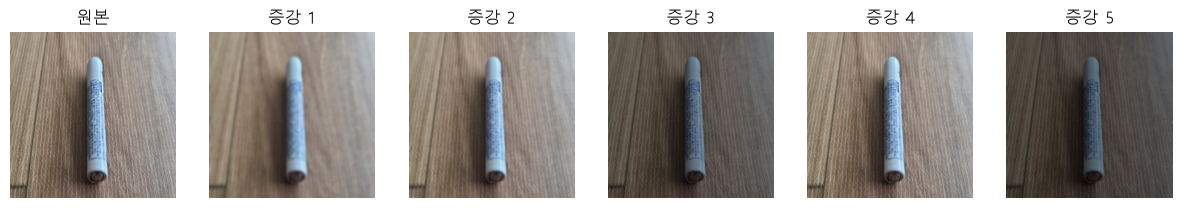

In [13]:
# [셀 목적] 학습 증강 예시 — 같은 사진에 증강을 여러 번 적용한 결과 (이미지 파일이 있을 때만 표시)
ex_path = next((ROOT / p for p in train_mix.path if (ROOT / p).exists()), None)  # 실제 있는 첫 학습 이미지
if ex_path is not None:
    show_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), dark_or_blur])
    img = Image.open(ex_path).convert("RGB")
    random.seed(0)
    torch.manual_seed(0)
    fig, ax = plt.subplots(1, 6, figsize=(15, 3))
    ax[0].imshow(img.resize((IMG_SIZE, IMG_SIZE)))
    ax[0].set_title("원본")
    for k in range(1, 6):
        ax[k].imshow(show_tf(img))
        ax[k].set_title(f"증강 {k}")
    for a in ax:
        a.axis("off")
    plt.show()
else:
    print("이미지 파일이 없어 예시를 생략")

## 7. 모델 정의 — ResNet18 + MLP 헤드, layer4만 미세조정
- ImageNet으로 사전학습된 ResNet18을 쓴다. 마지막 분류층을 MLP 헤드(512→256→128→12, ReLU)로 바꾼다.
- **layer4(마지막 블록)와 헤드만 학습**하고 앞쪽 층은 동결한다.
  - CPU 학습 시간을 줄이고, 데이터가 많지 않을 때 과적합을 막기 위해서다.
  - layer4를 풀면 어둡거나 흐린 쓰레기 사진의 특징을 새로 배울 수 있다.
- 동결된 층의 BatchNorm은 학습 중에도 eval 모드로 둔다. 이렇게 해야 ImageNet에서 구한 통계값이 바뀌지 않는다.

In [14]:
# [셀 목적] 최종 모델 생성 함수, 동결 BatchNorm 처리 함수 정의 + 학습 파라미터 수 확인
def build_final_model() -> nn.Module:
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)   # ImageNet 사전학습 가중치
    model.fc = nn.Sequential(                                           # 분류 헤드 512 → 256 → 128 → 12
        nn.Linear(model.fc.in_features, 256), nn.ReLU(),
        nn.Linear(256, 128), nn.ReLU(),
        nn.Linear(128, len(CLASSES)),
    )
    for name, p in model.named_parameters():                            # layer4 + 헤드만 학습
        p.requires_grad = name.startswith(("layer4", "fc"))
    return model


def set_train_mode(model: nn.Module):
    """학습 모드로 바꾸되, 동결된 부분의 BatchNorm은 eval로 둔다 (ImageNet 통계 유지)"""
    model.train()
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()


model = build_final_model()
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_all = sum(p.numel() for p in model.parameters())
print(model.fc)
print(f"학습 파라미터 {n_train:,} / 전체 {n_all:,} ({n_train / n_all:.1%})")

Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=12, bias=True)
)
학습 파라미터 8,559,500 / 전체 11,342,284 (75.5%)


## 8. 학습 — AdamW, 최대 10 epoch, 조기 종료
- 손실: CrossEntropy / 옵티마이저: AdamW (lr 1e-3, weight decay 1e-4) / batch 32 / seed 42
- **조기 종료 기준**: epoch마다 val과 val_ext 정확도의 평균을 잰다.
  - 이 평균이 가장 높은 epoch의 가중치를 저장한다.
  - 3 epoch 연속으로 나아지지 않으면 멈춘다.
  - val(깨끗한 사진)만 보면 외부 사진에 약한 모델이 뽑히기 때문에 둘을 함께 본다.
- `RUN_TRAINING = False`이면 저장된 가중치와 학습 기록을 불러온다. True로 다시 학습하면 `*_retrain` 이름으로 따로 저장한다. 제출 모델을 덮어쓰지 않기 위해서다.

In [15]:
# [셀 목적] 1 epoch 학습 함수, 평가 함수(손실·정확도·예측·확률), 조기 종료가 있는 전체 학습 함수 정의
def train_one_epoch(model, loader, criterion, optimizer):
    set_train_mode(model)
    n, correct, loss_sum = 0, 0, 0.0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        loss = criterion(out, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return loss_sum / n, correct / n


@torch.no_grad()
def evaluate(model, loader, criterion):
    """반환: 평균 손실, 정확도, 예측 클래스 번호, 정답 클래스 번호"""
    model.eval()
    n, correct, loss_sum, preds, labels = 0, 0, 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        loss_sum += criterion(out, y).item() * x.size(0)
        p = out.argmax(1)
        correct += (p == y).sum().item()
        n += x.size(0)
        preds.append(p.cpu())
        labels.append(y.cpu())
    return loss_sum / n, correct / n, torch.cat(preds).numpy(), torch.cat(labels).numpy()


def fit(train_df, val_df, val_ext_df, ckpt_path, epochs=10, patience=3, batch=32, lr=1e-3, weight_decay=1e-4):
    """최종 모델 학습. 조기 종료 기준 = (val acc + val_ext acc) / 2 가 가장 높은 epoch의 가중치 저장"""
    seed_everything(SEED)
    train_loader = make_loader(train_df, train_tf, batch, True)
    val_loader = make_loader(val_df, eval_tf, batch * 2, False)
    ext_loader = make_loader(val_ext_df, eval_tf, batch * 2, False)
    model = build_final_model().to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=weight_decay)
    hist, best, bad = [], -1.0, 0
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion)
        ex_loss, ex_acc, _, _ = evaluate(model, ext_loader, criterion)
        score = (va_acc + ex_acc) / 2
        hist.append(dict(epoch=ep, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc,
                         val_ext_loss=ex_loss, val_ext_acc=ex_acc, score=score, sec=time.perf_counter() - t0))
        print(f"ep{ep:02d} train {tr_loss:.4f}/{tr_acc:.4f}  val {va_loss:.4f}/{va_acc:.4f}  "
              f"val_ext {ex_loss:.4f}/{ex_acc:.4f}  기준 {score:.4f}  ({hist[-1]['sec']:.0f}s)")
        if score > best:
            best, bad = score, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            bad += 1
            if bad >= patience:
                print(f"조기 종료 (patience {patience})")
                break
    return pd.DataFrame(hist)

In [16]:
# [셀 목적] RUN_TRAINING=True면 학습 실행(약 74분, *_retrain으로 저장), False면 저장된 학습 기록 불러오기
criterion = nn.CrossEntropyLoss()
if RUN_TRAINING:
    retrain_ckpt = CKPT_PATH.with_name("final_model_retrain.pth")
    history = fit(keep_available(train_mix, "학습 데이터"), keep_available(val_df, "val"), keep_available(val_ext, "val_ext"), retrain_ckpt)
    history.to_csv(MODEL_DIR / "train_history_retrain.csv", index=False)
    print("재학습 완료 →", retrain_ckpt, "(아래 평가는 제출 모델 기준)")
else:
    history = pd.read_csv(MODEL_DIR / "train_history.csv")
    print("저장된 학습 기록 사용:", MODEL_DIR / "train_history.csv")
history.drop(columns=["lr"], errors="ignore").round(4)

저장된 학습 기록 사용: D:\데이터 분석\빅데이터_프로그래밍\01_coding\RESULT\final_model\train_history.csv


,epoch,train_loss,train_acc,val_loss,val_acc,val_ext_loss,val_ext_acc,score,sec
0,1,0.8035,0.7468,0.3534,0.8891,0.7362,0.768,0.8286,440.4162
1,2,0.4630,0.8492,0.2446,0.9287,0.5280,0.822,0.8753,439.6189
2,3,0.3219,0.8992,0.3189,0.9102,0.5124,0.840,0.8751,439.4368
3,4,0.2528,0.9189,0.3018,0.9132,0.4546,0.848,0.8806,438.4132
4,5,0.1993,0.9368,0.3349,0.9119,0.4545,0.850,0.8810,438.5792
5,6,0.1641,0.9479,0.2220,0.9446,0.4795,0.876,0.9103,438.7833
6,7,0.1364,0.9578,0.2523,0.9360,0.5780,0.860,0.8980,441.5753
7,8,0.1214,0.9632,0.2318,0.9446,0.4554,0.884,0.9143,441.6881
8,9,0.1028,0.9688,0.3123,0.9274,0.4986,0.870,0.8987,437.4428
9,10,0.0940,0.9713,0.2134,0.9493,0.4574,0.890,0.9196,439.7833


## 9. 학습 곡선과 과적합 확인
과적합이면 train loss는 계속 내려가는데 val loss가 다시 오르고, train과 val 정확도의 차이가 커진다.

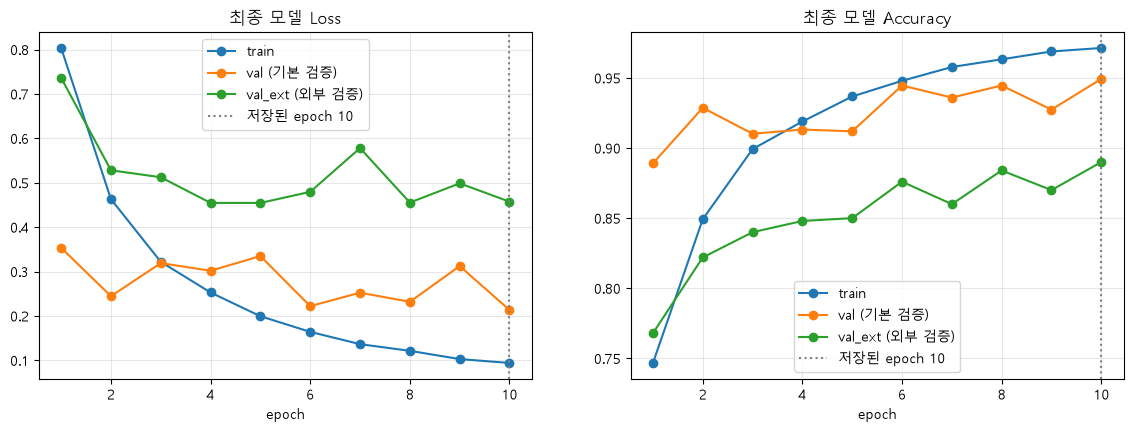

저장된 epoch 10: train acc 0.9713 / val acc 0.9493 → 차이 +0.0220
val loss 최저 epoch = 10 / 마지막 epoch = 10


In [17]:
# [셀 목적] epoch별 손실·정확도 곡선(train / val / val_ext)과 저장된 epoch 표시, 과적합 지표(train−val 정확도 차이) 출력
best_ep = int(history.loc[history.score.idxmax(), "epoch"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for col, lab in [("train", "train"), ("val", "val (기본 검증)"), ("val_ext", "val_ext (외부 검증)")]:
    ax[0].plot(history.epoch, history[f"{col}_loss"], "-o", label=lab)
    ax[1].plot(history.epoch, history[f"{col}_acc"], "-o", label=lab)
for a, t in zip(ax, ["Loss", "Accuracy"]):
    a.axvline(best_ep, color="gray", ls=":", label=f"저장된 epoch {best_ep}")
    a.set(title=f"최종 모델 {t}", xlabel="epoch")
    a.grid(alpha=0.3)
    a.legend()
plt.show()
b = history[history.epoch == best_ep].iloc[0]
print(f"저장된 epoch {best_ep}: train acc {b.train_acc:.4f} / val acc {b.val_acc:.4f} → 차이 {b.train_acc - b.val_acc:+.4f}")
print(f"val loss 최저 epoch = {int(history.loc[history.val_loss.idxmin(), 'epoch'])} / 마지막 epoch = {int(history.epoch.max())}")

**해석**: train과 val의 정확도 차이는 약 2%p로 작고, val loss는 마지막 epoch까지 다시 오르지 않았다. 따라서 뚜렷한 과적합은 없다. 마지막 epoch(10)에서 최고점이 나왔으므로 더 학습할 여지는 있다.

## 10. 검증 평가 — val / val_ext / val_hard / val_avg
저장된 최종 모델 가중치로 세 검증셋을 평가한다.

| 지표 | 데이터 | 의미 |
|---|---|---|
| **val** | Kaggle 원본 검증 2,327장 | 깨끗한 사진에서의 정확도 |
| **val_ext** | 외부 실사 사진 500장 (RealWaste·AI Hub, clothes·shoes 없음) | 다른 촬영 환경·배경에서의 정확도 |
| **val_hard** | 손상 사진 1,200장 (흐림·어둡게·빛번짐) | 어둡거나 흐린 사진에서의 정확도 |
| **val_avg** | (val + val_ext + val_hard) / 3 | 세 검증 지표의 평균. 모델 선택 기준 |

val_hard는 160px로 만든 이미지를 224px로 키워서 평가하므로, 실제보다 약간 불리하게 나온다.

In [18]:
# [셀 목적] 제출 모델 가중치를 불러와 val / val_ext / val_hard를 평가하고 val_avg(세 지표 평균) 계산
assert CKPT_PATH.exists(), f"모델 가중치 없음: {CKPT_PATH} (RUN_TRAINING=True로 학습 필요)"
final_model = build_final_model()
final_model.load_state_dict(torch.load(CKPT_PATH, map_location="cpu"))
final_model = final_model.to(DEVICE).eval()

eval_sets = {k: keep_available(df, k) for k, df in {"val": val_df, "val_ext": val_ext, "val_hard": val_hard}.items()}
preds = {}
rows = []
for k, df in eval_sets.items():
    loss, acc, p, y = evaluate(final_model, make_loader(df, eval_tf, 64, False), criterion)
    preds[k] = (df.reset_index(drop=True), p, y)
    rows.append({"검증셋": k, "장수": len(df), "loss": round(loss, 4), "accuracy": round(acc, 4)})
scores = pd.DataFrame(rows).set_index("검증셋")
val_avg = scores.accuracy.mean()
scores.loc["val_avg (세 지표 평균)", "accuracy"] = round(val_avg, 4)
scores

,장수,loss,accuracy
검증셋,,,
val,2327.0,0.2134,0.9493
val_ext,500.0,0.4574,0.8900
val_hard,1200.0,0.6025,0.8342
val_avg (세 지표 평균),NaN,NaN,0.8912


In [19]:
# [셀 목적] 클래스별 정확도(검증셋별)와 손상 종류별 정확도 표
per_class = pd.DataFrame({k: pd.Series({c: (p[y == i] == i).mean() if (y == i).any() else np.nan
                                        for i, c in enumerate(CLASSES)}) for k, (_, p, y) in preds.items()}).round(3)
d, p, y = preds["val_hard"]
by_corr = d.assign(ok=(p == y)).groupby("corruption").ok.agg(["mean", "size"]).round(4)
by_corr.index = by_corr.index.map({"blur": "흐림", "dark": "어둡게", "glare": "빛번짐"})
by_corr.columns = ["정확도", "장수"]
display(per_class)
by_corr

,val,val_ext,val_hard
battery,0.979,0.98,0.83
biological,0.993,1.00,0.94
brown-glass,0.967,0.90,0.84
cardboard,0.902,0.76,0.78
clothes,0.981,NaN,0.93
green-glass,0.958,0.94,0.90
metal,0.905,0.90,0.78
paper,0.936,0.88,0.75
plastic,0.806,0.70,0.76
shoes,0.959,NaN,0.92


,정확도,장수
corruption,,
흐림,0.7797,395
어둡게,0.8284,408
빛번짐,0.8942,397


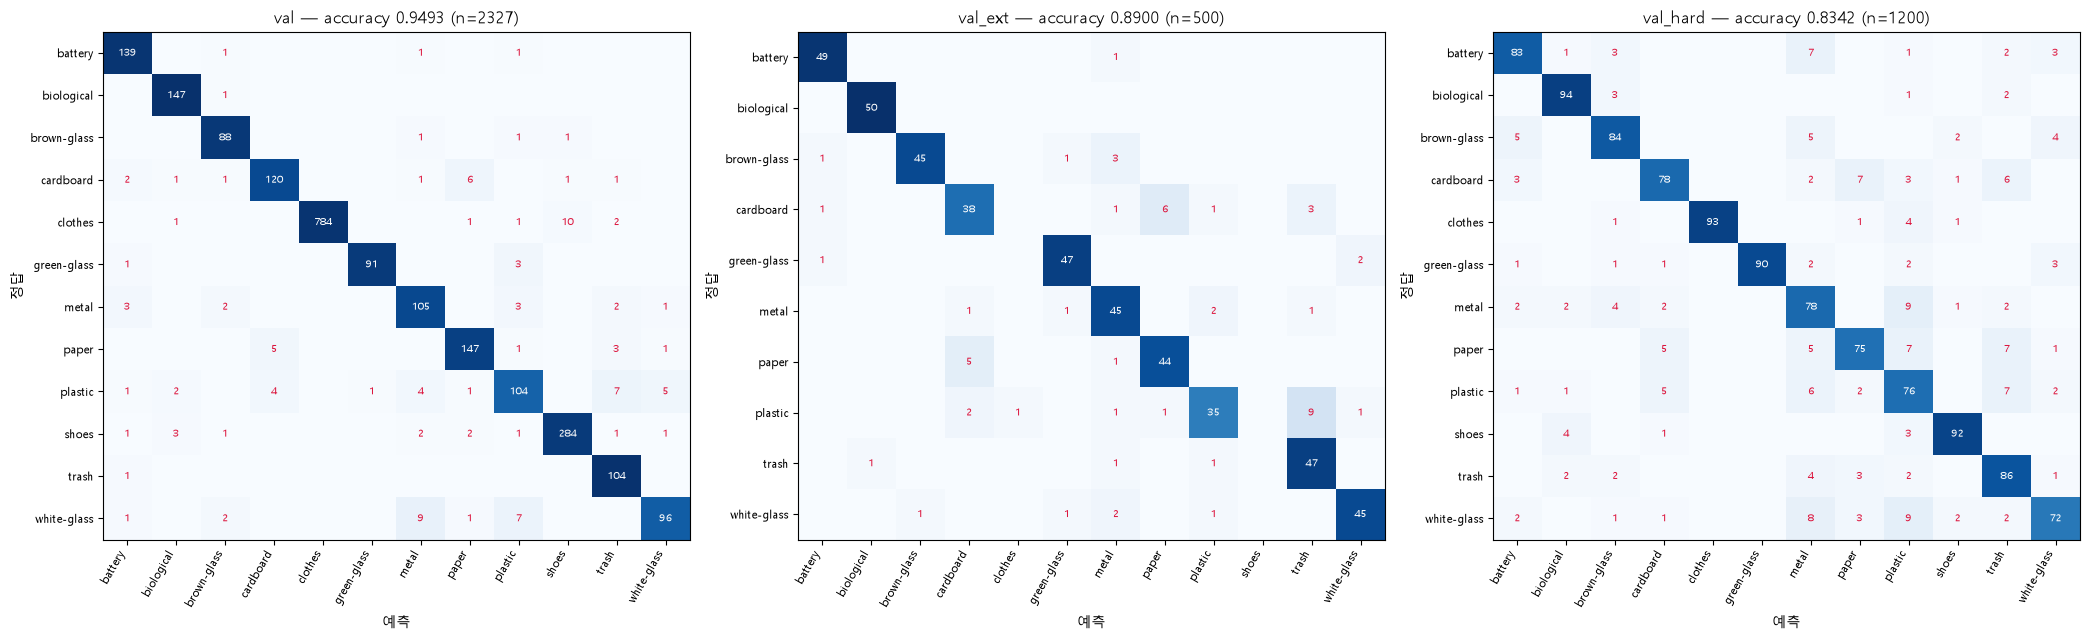

In [20]:
# [셀 목적] 혼동행렬 그리기 함수 정의 + 세 검증셋의 혼동행렬 (색 = 정답 행 기준 비율, 숫자 = 장수, 빨강 = 오답)
def plot_cm(ax, cm: pd.DataFrame, title: str):
    v = cm.values
    rate = v / v.sum(1, keepdims=True)
    ax.imshow(rate, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if v[i, j]:
                ax.text(j, i, v[i, j], ha="center", va="center", fontsize=7,
                        color="white" if rate[i, j] > 0.5 else ("crimson" if cm.index[i] != cm.columns[j] else "black"))
    ax.set_xticks(range(v.shape[1]), cm.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(v.shape[0]), cm.index, fontsize=8)
    ax.set(title=title, xlabel="예측", ylabel="정답")


def confusion(labels, preds_) -> pd.DataFrame:
    t, p_ = np.array(CLASSES)[labels], np.array(CLASSES)[preds_]
    present = [c for c in CLASSES if c in set(t)]
    return pd.crosstab(pd.Series(t, name="정답"), pd.Series(p_, name="예측")).reindex(index=present, columns=CLASSES, fill_value=0)


fig, ax = plt.subplots(1, 3, figsize=(21, 6.5))
for a, (k, (_, p, y)) in zip(ax, preds.items()):
    plot_cm(a, confusion(y, p), f"{k} — accuracy {(p == y).mean():.4f} (n={len(y)})")
plt.tight_layout()
plt.show()

## 11. 최종 TEST (1회)
| 지표 | 데이터 | 의미 |
|---|---|---|
| **test** | Kaggle 원본 테스트 2,328장 (12클래스) | 깨끗한 사진에서의 최종 정확도 |
| **test_ext** | 외부 실사 사진 360장 (9클래스, biological·clothes·shoes 없음) | 다른 촬영 환경에서의 최종 정확도 |

TEST는 모델 설계와 선택이 모두 끝난 뒤 **최종 모델로 한 번만** 평가했다. 이 노트북은 그때 저장한 결과(`RESULT/final_test/`)를 불러온다.

평가 코드는 `RUN_FINAL_TEST = True`일 때만 실행된다. 이미 결과 파일이 있으면 덮어쓰지 않도록 막아 두었다.

In [21]:
# [셀 목적] (RUN_FINAL_TEST=True이고 결과가 없을 때만) test·test_ext 평가 후 저장 / 기본은 저장된 1회 결과 불러오기
test_sets = {"test": test_df, "test_ext": test_ext}
result_path = FINAL_DIR / "final_test.json"
if RUN_FINAL_TEST:
    assert not result_path.exists(), "TEST는 이미 1회 평가함 — 다시 평가하지 않는다"
    FINAL_DIR.mkdir(parents=True, exist_ok=True)
    res = {}
    for k, df in test_sets.items():
        df = keep_available(df, k)
        _, acc, p, y = evaluate(final_model, make_loader(df, eval_tf, 64, False), criterion)
        res[k] = {"acc": round(acc, 4), "n": len(df)}
        confusion(y, p).to_csv(FINAL_DIR / f"final_{k}_confusion.csv", encoding="utf-8-sig")
    json.dump(res, open(result_path, "w", encoding="utf-8"), ensure_ascii=False, indent=1)

final = json.load(open(result_path, encoding="utf-8"))
test_cm = {k: pd.read_csv(FINAL_DIR / f"final_{k}_confusion.csv", index_col=0) for k in test_sets}
test_cm = {k: cm.reindex(index=[c for c in CLASSES if c in cm.index], columns=CLASSES, fill_value=0) for k, cm in test_cm.items()}
for k, cm in test_cm.items():  # 저장된 혼동행렬과 정확도가 서로 맞는지 확인
    assert cm.values.sum() == final[k]["n"]
    assert abs(np.trace(cm[cm.index].values) / cm.values.sum() - final[k]["acc"]) < 1e-3
pd.DataFrame({k: {"장수": final[k]["n"], "accuracy": final[k]["acc"]} for k in test_sets}).T

,장수,accuracy
test,2328.0,0.9394
test_ext,360.0,0.9083


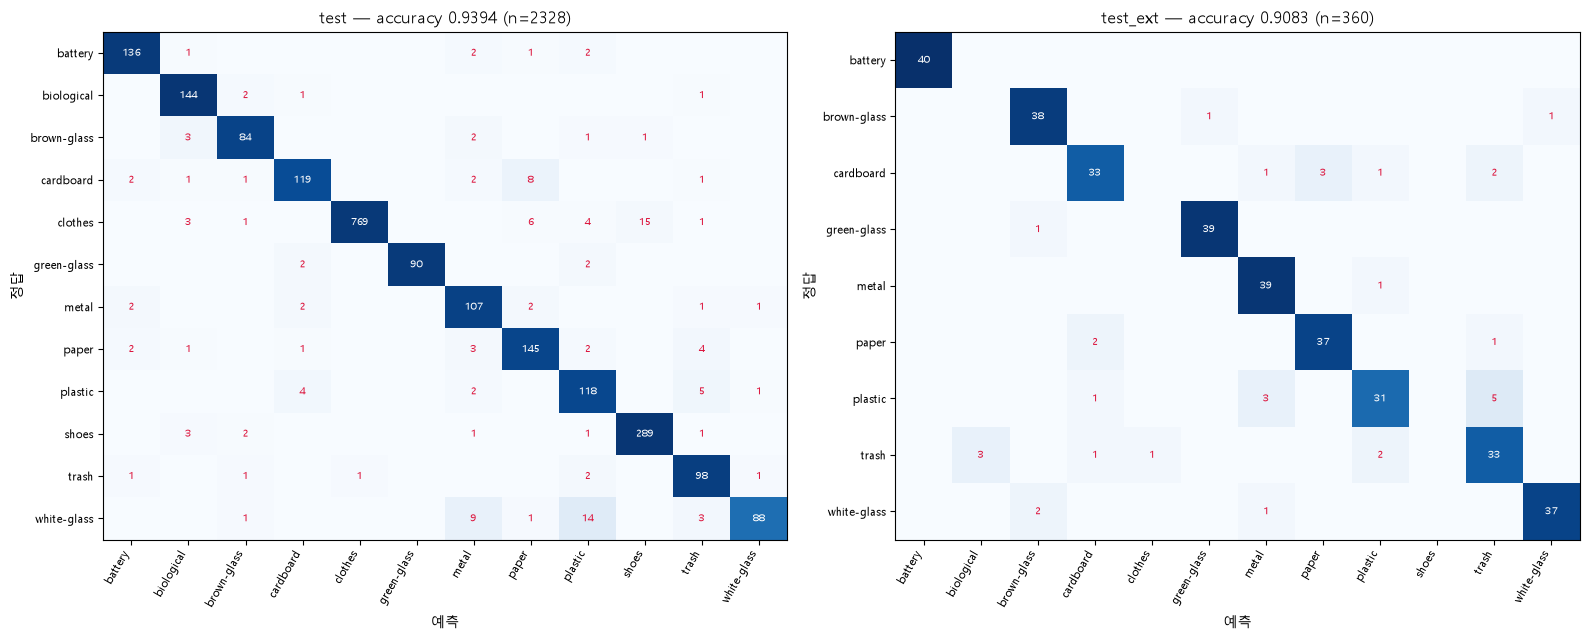

In [22]:
# [셀 목적] TEST 혼동행렬 2개 (test, test_ext)
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
for a, (k, cm) in zip(ax, test_cm.items()):
    plot_cm(a, cm, f"{k} — accuracy {final[k]['acc']:.4f} (n={final[k]['n']})")
plt.tight_layout()
plt.show()

In [23]:
# [셀 목적] TEST 클래스별 정밀도(오탐이 적을수록 높음)·재현율(놓친 게 적을수록 높음)·F1 표와 가장 많이 헷갈린 클래스 쌍
def class_report(cm: pd.DataFrame) -> pd.DataFrame:
    tp = np.array([cm.loc[c, c] for c in cm.index])
    pred_tot = cm[cm.index].sum(axis=0).values
    true_tot = cm.sum(axis=1).values
    prec = np.divide(tp, pred_tot, out=np.full(len(tp), np.nan), where=pred_tot > 0)
    rec = tp / true_tot
    f1 = np.where(prec + rec > 0, 2 * prec * rec / (prec + rec), 0)
    return pd.DataFrame(dict(장수=true_tot, 정밀도=prec, 재현율=rec, F1=f1, 오탐=pred_tot - tp, 미탐=true_tot - tp),
                        index=cm.index).round(3)


def top_confusions(cm: pd.DataFrame, k=6) -> pd.DataFrame:
    s = cm.stack()
    s = s[[a != b for a, b in s.index]]
    s = s[s > 0].sort_values(ascending=False).head(k)
    return pd.DataFrame({"정답 → 예측": [f"{a} → {b}" for a, b in s.index], "장수": s.values})


display(pd.concat({k: class_report(cm) for k, cm in test_cm.items()}, axis=1))
pd.concat({k: top_confusions(cm) for k, cm in test_cm.items()}, axis=1)

test                              test_ext                               
              장수    정밀도    재현율     F1  오탐  미탐       장수    정밀도    재현율     F1   오탐   미탐
label                                                                                
battery      142  0.951  0.958  0.954   7   6     40.0  1.000  1.000  1.000  0.0  0.0
biological   148  0.923  0.973  0.947  12   4      NaN    NaN    NaN    NaN  NaN  NaN
brown-glass   91  0.913  0.923  0.918   8   7     40.0  0.927  0.950  0.938  3.0  2.0
cardboard    134  0.922  0.888  0.905  10  15     40.0  0.892  0.825  0.857  4.0  7.0
clothes      799  0.999  0.962  0.980   1  30      NaN    NaN    NaN    NaN  NaN  NaN
green-glass   94  1.000  0.957  0.978   0   4     40.0  0.975  0.975  0.975  1.0  1.0
metal        115  0.836  0.930  0.881  21   8     40.0  0.886  0.975  0.929  5.0  1.0
paper        158  0.890  0.918  0.903  18  13     40.0  0.925  0.925  0.925  3.0  3.0
plastic      130  0.808  0.908  0.855  28  12     40.0  0.886  0.775  0.827  4.0  9.0
shoes        297  0.948  0.973  0.960  16   8      NaN    NaN    NaN    NaN  NaN  NaN
trash        104  0.852  0.942  0.895  17   6     40.0  0.805  0.825  0.815  8.0  7.0
white-glass  116  0.967  0.759  0.850   3  28     40.0  0.974  0.925  0.949  1.0  3.0

test                test_ext   
                 정답 → 예측  장수             정답 → 예측 장수
0        clothes → shoes  15     plastic → trash  5
1  white-glass → plastic  14   cardboard → paper  3
2    white-glass → metal   9     plastic → metal  3
3      cardboard → paper   8  trash → biological  3
4        clothes → paper   6     trash → plastic  2
5        plastic → trash   5   paper → cardboard  2

## 12. 결론
- 최종 모델은 Kaggle test에서 **0.9394**, 외부 실사 test_ext에서 **0.9083**을 기록했다. 검증 점수(val 0.949, val_ext 0.890)와 비슷해 과적합이나 선택 편향은 작다.
- 외부 실사 데이터를 섞고, 어둡게·흐림 증강을 쓰고, layer4를 미세조정하고, 입력을 224px로 키운 것이 외부·손상 사진 성능을 끌어올렸다. 손상 검증셋에서 어둡게 0.83, 흐림 0.78, 빛번짐 0.89를 기록했다.
- **약점**:
  - 투명 유리(white-glass)를 metal·plastic으로 혼동한다.
  - 실사 사진(RealWaste)의 plastic·cardboard·trash 사이 혼동이 많다.
- **한계**:
  - 외부 검증·테스트셋에는 clothes·shoes(테스트는 biological 포함)가 없다.
  - 작은 물체·넓은 배경, 오염·찌그러짐 조건은 따로 표시가 없어 분리해 측정하지 못했다.